# K-Means Clustering

In [6]:
# load libraries 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans

In [3]:
# load dataset
df = pd.read_csv('Mall_Customers.csv')
df.sample(5)

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
56,57,Female,51,44,50
1,2,Male,21,15,81
22,23,Female,46,25,5
40,41,Female,65,38,35
46,47,Female,50,40,55


In [4]:
fields = df.iloc[:,[3,4]].values
fields

array([[ 15,  39],
       [ 15,  81],
       [ 16,   6],
       [ 16,  77],
       [ 17,  40],
       [ 17,  76],
       [ 18,   6],
       [ 18,  94],
       [ 19,   3],
       [ 19,  72],
       [ 19,  14],
       [ 19,  99],
       [ 20,  15],
       [ 20,  77],
       [ 20,  13],
       [ 20,  79],
       [ 21,  35],
       [ 21,  66],
       [ 23,  29],
       [ 23,  98],
       [ 24,  35],
       [ 24,  73],
       [ 25,   5],
       [ 25,  73],
       [ 28,  14],
       [ 28,  82],
       [ 28,  32],
       [ 28,  61],
       [ 29,  31],
       [ 29,  87],
       [ 30,   4],
       [ 30,  73],
       [ 33,   4],
       [ 33,  92],
       [ 33,  14],
       [ 33,  81],
       [ 34,  17],
       [ 34,  73],
       [ 37,  26],
       [ 37,  75],
       [ 38,  35],
       [ 38,  92],
       [ 39,  36],
       [ 39,  61],
       [ 39,  28],
       [ 39,  65],
       [ 40,  55],
       [ 40,  47],
       [ 40,  42],
       [ 40,  42],
       [ 42,  52],
       [ 42,  60],
       [ 43,

In [5]:
# try several values of number of clusters to find the more optimal
wcss = []
for index in range(1, 11):
    kmeans = KMeans(n_clusters=index, init='k-means++', random_state=2)
    kmeans.fit(fields)

    wcss.append(kmeans.inertia_)


Text(0, 0.5, 'WCSS')

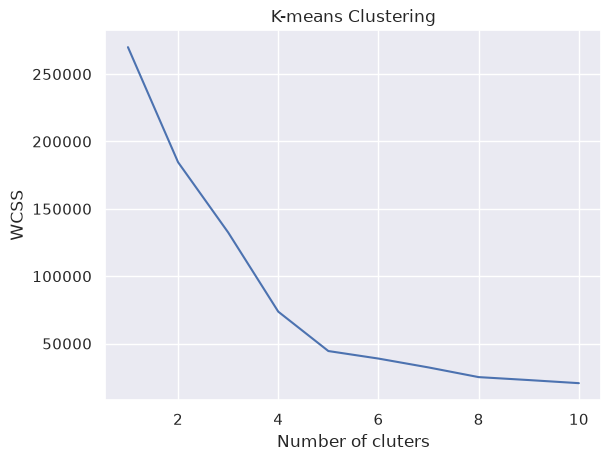

In [ ]:
# plot the Jambu shoulder 
sns.set_theme()
plt.plot(range(1, 11), wcss)
plt.title('K-means Clustering')
plt.xlabel('Number of cluters')
plt.ylabel('WCSS')


In [8]:
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=2)
cluster_values = kmeans.fit_predict(fields)
cluster_values

array([2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4,
       2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 0,
       2, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 1, 3, 0, 3, 1, 3, 1, 3,
       0, 3, 1, 3, 1, 3, 1, 3, 1, 3, 0, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3], dtype=int32)

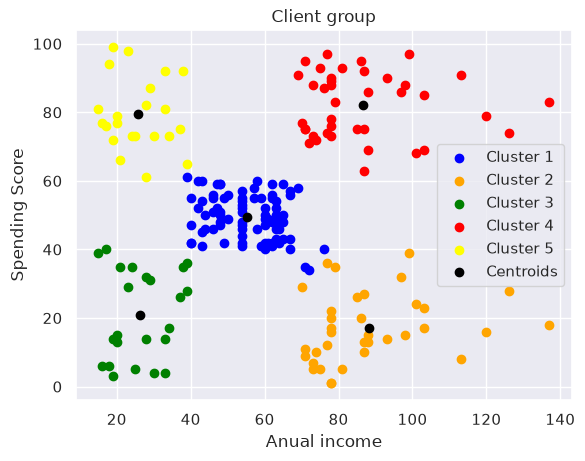

In [12]:
# Plot the cluster 
plt.scatter(fields[cluster_values==0, 0], fields[cluster_values==0, 1], c = 'blue', label = 'Cluster 1')
plt.scatter(fields[cluster_values==1, 0], fields[cluster_values==1, 1], c = 'orange', label = 'Cluster 2')
plt.scatter(fields[cluster_values==2, 0], fields[cluster_values==2, 1], c = 'green', label = 'Cluster 3')
plt.scatter(fields[cluster_values==3, 0], fields[cluster_values==3, 1], c = 'red', label = 'Cluster 4')
plt.scatter(fields[cluster_values==4, 0], fields[cluster_values==4, 1], c = 'yellow', label = 'Cluster 5')

plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c = 'black', label = 'Centroids')

plt.title('Client group')
plt.xlabel('Anual income')
plt.ylabel('Spending Score')
plt.legend()

In [13]:
# load silhouette library
from sklearn import datasets
from sklearn.metrics import silhouette_score


In [15]:
X = df.iloc[:, [3,4]].to_numpy()

for j in range(2, 12):
    kmeans = KMeans(n_clusters = j, random_state=2)
    kmeans.fit_predict(X)

    # calculate silhouette score
    score = silhouette_score(X, kmeans.labels_, metric= 'euclidean')
    print(f'Score silhouette, k = {j},  score: {score:.2f} ')
    

Score silhouette, k = 2,  score: 0.38 
Score silhouette, k = 3,  score: 0.38 
Score silhouette, k = 4,  score: 0.49 
Score silhouette, k = 5,  score: 0.55 
Score silhouette, k = 6,  score: 0.46 
Score silhouette, k = 7,  score: 0.45 
Score silhouette, k = 8,  score: 0.46 
Score silhouette, k = 9,  score: 0.45 
Score silhouette, k = 10,  score: 0.45 
Score silhouette, k = 11,  score: 0.40 


# K-means for three columns in the original dataset


In [16]:
fields2 = df.iloc[:, [2,3,4]].values
fields2

array([[ 19,  15,  39],
       [ 21,  15,  81],
       [ 20,  16,   6],
       [ 23,  16,  77],
       [ 31,  17,  40],
       [ 22,  17,  76],
       [ 35,  18,   6],
       [ 23,  18,  94],
       [ 64,  19,   3],
       [ 30,  19,  72],
       [ 67,  19,  14],
       [ 35,  19,  99],
       [ 58,  20,  15],
       [ 24,  20,  77],
       [ 37,  20,  13],
       [ 22,  20,  79],
       [ 35,  21,  35],
       [ 20,  21,  66],
       [ 52,  23,  29],
       [ 35,  23,  98],
       [ 35,  24,  35],
       [ 25,  24,  73],
       [ 46,  25,   5],
       [ 31,  25,  73],
       [ 54,  28,  14],
       [ 29,  28,  82],
       [ 45,  28,  32],
       [ 35,  28,  61],
       [ 40,  29,  31],
       [ 23,  29,  87],
       [ 60,  30,   4],
       [ 21,  30,  73],
       [ 53,  33,   4],
       [ 18,  33,  92],
       [ 49,  33,  14],
       [ 21,  33,  81],
       [ 42,  34,  17],
       [ 30,  34,  73],
       [ 36,  37,  26],
       [ 20,  37,  75],
       [ 65,  38,  35],
       [ 24,  38

In [17]:
# load decomposition pca library

from sklearn import decomposition

pca = decomposition.PCA(n_components=2)
pca.fit(fields2)
fields2 = pca.transform(fields2)
fields2

array([[-3.18705078e+01, -3.30014253e+01],
       [ 7.63396908e-01, -5.68438653e+01],
       [-5.74087256e+01, -1.31229362e+01],
       [-2.16989648e+00, -5.34779049e+01],
       [-3.21749197e+01, -3.03870050e+01],
       [-2.17827777e+00, -5.22265808e+01],
       [-5.90660565e+01, -9.54170669e+00],
       [ 1.23693261e+01, -6.16176843e+01],
       [-6.63156568e+01, -3.21359934e+00],
       [-5.65677534e+00, -4.72664534e+01],
       [-5.82366179e+01, -9.13375312e+00],
       [ 1.46202592e+01, -6.21072940e+01],
       [-5.51612126e+01, -1.00779778e+01],
       [-4.30660584e-03, -5.01134367e+01],
       [-5.27647474e+01, -1.16804199e+01],
       [ 1.94563480e+00, -5.15231943e+01],
       [-3.45062349e+01, -2.37600734e+01],
       [-7.30573032e+00, -4.35158724e+01],
       [-4.12574933e+01, -1.64734320e+01],
       [ 1.61888268e+01, -5.82998775e+01],
       [-3.27403118e+01, -2.13349462e+01],
       [-9.82702739e-01, -4.44533143e+01],
       [-5.78102821e+01, -1.86854579e+00],
       [-1.

In [18]:
# try several values of number of clusters to find the more optimal
wcss2 = []
for index in range(1, 11):
    kmeans = KMeans(n_clusters=index, init='k-means++', random_state=2)
    kmeans.fit(fields2)

    wcss2.append(kmeans.inertia_)

Text(0, 0.5, 'WCSS')

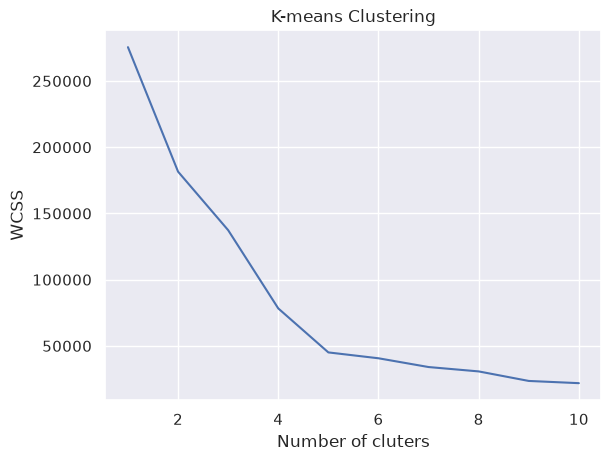

In [19]:
# plot the Jambu shoulder 
sns.set_theme()
plt.plot(range(1, 11), wcss2)
plt.title('K-means Clustering')
plt.xlabel('Number of cluters')
plt.ylabel('WCSS')


In [20]:
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=2)
cluster_values = kmeans.fit_predict(fields2)
cluster_values

array([2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4,
       2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 0,
       2, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 3, 0, 3, 1, 3, 1, 3,
       0, 3, 1, 3, 1, 3, 1, 3, 1, 3, 0, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3], dtype=int32)

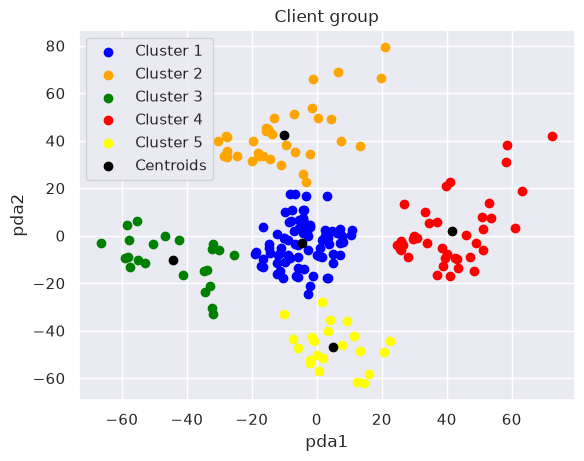

In [22]:
# Plot the cluster 
plt.scatter(fields2[cluster_values==0, 0], fields2[cluster_values==0, 1], c = 'blue', label = 'Cluster 1')
plt.scatter(fields2[cluster_values==1, 0], fields2[cluster_values==1, 1], c = 'orange', label = 'Cluster 2')
plt.scatter(fields2[cluster_values==2, 0], fields2[cluster_values==2, 1], c = 'green', label = 'Cluster 3')
plt.scatter(fields2[cluster_values==3, 0], fields2[cluster_values==3, 1], c = 'red', label = 'Cluster 4')
plt.scatter(fields2[cluster_values==4, 0], fields2[cluster_values==4, 1], c = 'yellow', label = 'Cluster 5')

plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c = 'black', label = 'Centroids')

plt.title('Client group')
plt.xlabel('pda1')
plt.ylabel('pda2')
plt.legend()